In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Dataset analysis

In [2]:
with open("SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/original_rt_snippets.txt", 'r') as f :
    print(len(f.read().split(".")))

14044


In [3]:
with open("SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/dictionary.txt", 'r') as dict :
    print(len(dict.readlines()))

239232


In [4]:
with open("SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/sentiment_labels.txt", 'r') as labels :
    print(len(labels.readlines()))

239233


We create a dataframe that merges the sentences of the dataset with their ids and the associated sentiment value

In [5]:
dictionary = "SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/dictionary.txt"
labels = "SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/sentiment_labels.txt"

df_dict = pd.read_csv(
    dictionary,
    sep="|",
    header=None,
    names=["text", "phrase_id"]
)

df_labels = pd.read_csv(
    labels,
    sep="|",
    names=["phrase_id", "sentiment_value"]
)
df_labels = df_labels.iloc[1:]
df_labels['phrase_id'] = df_labels['phrase_id'].astype("int64")

df = df_dict.merge(df_labels, on="phrase_id")

print(df)

                                                     text  phrase_id  \
0                                                       !          0   
1                                                     ! '      22935   
2                                                    ! ''      18235   
3                                                  ! Alas     179257   
4                                             ! Brilliant      22936   
...                                                   ...        ...   
239227  zoning ordinances to protect your community fr...     220441   
239228                                          zzzzzzzzz     179256   
239229                                               élan     220442   
239230                                                  É     220443   
239231                   É um passatempo descompromissado     220444   

       sentiment_value  
0                  0.5  
1              0.52778  
2                  0.5  
3              0.44444  
4         

Now we can more easily gather information from the dataset

In [6]:
df.shape

(239232, 3)

In [7]:
df.isna().sum()

text               1
phrase_id          0
sentiment_value    0
dtype: int64

In [8]:
df[df['text'].isna()]

,text,phrase_id,sentiment_value
42077,NaN,67853,0.5


Looks like there is a missing value for in the text column. When looking into the `dictionary.txt` file it appears that the sentence with the id 67863 is "None" which has been handled by the pandas library as a missing value, let's fix that.

In [9]:
df.loc[42077, 'text'] = "None"

Let's take a look at the sentiment distribution

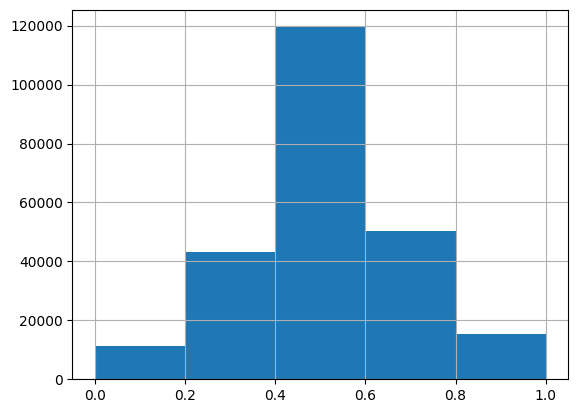

In [10]:
bin_edges = [0, 0.2, 0.4, 0.6, 0.8, 1]

df["sentiment_value"] = pd.to_numeric(df["sentiment_value"], errors='coerce')
df["sentiment_value"].hist(bins=bin_edges)

plt.xticks(bin_edges)

plt.show()

Sentence lenght

In [11]:
df["n_words"] = df["text"].str.split().str.len()
df["n_words"].describe()

count    239232.000000
mean          7.758088
std           7.488960
min           1.000000
25%           2.000000
50%           5.000000
75%          10.000000
max          56.000000
Name: n_words, dtype: float64

A lot of phrases included in the `dictionary.txt` just contain a small amount of words. We will start by only using full sentences as the data will be less noisy, for that we will use the sentences contained in `datasetSentences.txt`.

In [12]:
sentences = "SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/datasetSentences.txt"
split = "SST2-Data/SST2-Data/stanfordSentimentTreebank/stanfordSentimentTreebank/datasetSplit.txt"

df_sentences = pd.read_csv(sentences, sep='\t')
df_split = pd.read_csv(split)

In [13]:
df_split

,sentence_index,splitset_label
0,1,1
1,2,1
2,3,2
3,4,2
4,5,2
...,...,...
11850,11851,1
11851,11852,1
11852,11853,1
11853,11854,1


We will now use the 11 855 sentences in the `DatasetSentences.txt` file

In [14]:
df_sentences['sentence'] = df_sentences['sentence'].str.strip()
df_dict['text'] = df_dict['text'].str.strip()

In [15]:
df2 = df_sentences.merge(df_dict, left_on='sentence', right_on='text', how='left')
#df2 = df2.drop(columns=['text'])

In [16]:
print(df_dict[df_dict['phrase_id']==13924]['text'].item())

But in Imax 3-D , the clichés disappear into the vertiginous perspectives opened up by the photography .


In [17]:
print(df_sentences[df_sentences['sentence_index']==174]['sentence'].item())

-LRB- But it 's -RRB- worth recommending because of two marvelous performances by Michael Caine and Brendan Fraser .


In [18]:
df2.isna().sum()

sentence_index      0
sentence            0
text              569
phrase_id         569
dtype: int64

In [19]:
df2[df2['phrase_id'].isna()]

,sentence_index,sentence,text,phrase_id
102,103,"But in Imax 3-D , the clichÃ©s disappear into ...",NaN,NaN
173,174,-LRB- But it 's -RRB- worth recommending becau...,NaN,NaN
256,257,JirÃ­ Hubac 's script is a gem .,NaN,NaN
271,272,You would n't call The Good Girl a date movie ...,NaN,NaN
286,287,"An incendiary , deeply thought-provoking look ...",NaN,NaN
...,...,...,...,...
11802,11803,-LRB- A -RRB- mess .,NaN,NaN
11815,11816,-LRB- L -RRB- ame and unnecessary .,NaN,NaN
11817,11818,-LRB- A -RRB- crushing disappointment .,NaN,NaN
11839,11840,-LRB- A -RRB- slummer .,NaN,NaN


In [20]:
df2 = df2.merge(df_labels, on='phrase_id', how='left')

df2 = df2.merge(df_split, on='sentence_index')

In [21]:
df2

,sentence_index,sentence,text,phrase_id,sentiment_value,splitset_label
0,1,The Rock is destined to be the 21st Century 's...,The Rock is destined to be the 21st Century 's...,226166.0,0.69444,1
1,2,The gorgeously elaborate continuation of `` Th...,The gorgeously elaborate continuation of `` Th...,226300.0,0.83333,1
2,3,Effective but too-tepid biopic,Effective but too-tepid biopic,13995.0,0.51389,2
3,4,If you sometimes like to go to the movies to h...,If you sometimes like to go to the movies to h...,14123.0,0.73611,2
4,5,"Emerges as something rare , an issue movie tha...","Emerges as something rare , an issue movie tha...",13999.0,0.86111,2
...,...,...,...,...,...,...
11850,11851,A real snooze .,A real snooze .,222071.0,0.11111,1
11851,11852,No surprises .,No surprises .,225165.0,0.22222,1
11852,11853,We 've seen the hippie-turned-yuppie plot befo...,We 've seen the hippie-turned-yuppie plot befo...,226985.0,0.75,1
11853,11854,Her fans walked out muttering words like `` ho...,Her fans walked out muttering words like `` ho...,223632.0,0.13889,1


Cleaning text function

In [22]:
def clean_sst_text(text):
    if pd.isna(text):
        return text

    # Fix bracket tokens
    text = text.replace("-LRB-", "(")
    text = text.replace("-RRB-", ")")
    text = text.replace("-LSB-", "[")
    text = text.replace("-RSB-", "]")

    # Fix encoding corruption
    try:
        text = text.encode("latin1").decode("utf8")
    except:
        pass

    # normalize spaces
    text = " ".join(text.split())

    return text

In [23]:
df_sentences['clean text'] = df_sentences['sentence'].apply(clean_sst_text)
df_dict['clean text'] = df_dict['text'].apply(clean_sst_text)

In [24]:
df_sentences

,sentence_index,sentence,clean text
0,1,The Rock is destined to be the 21st Century 's...,The Rock is destined to be the 21st Century 's...
1,2,The gorgeously elaborate continuation of `` Th...,The gorgeously elaborate continuation of `` Th...
2,3,Effective but too-tepid biopic,Effective but too-tepid biopic
3,4,If you sometimes like to go to the movies to h...,If you sometimes like to go to the movies to h...
4,5,"Emerges as something rare , an issue movie tha...","Emerges as something rare , an issue movie tha..."
...,...,...,...
11850,11851,A real snooze .,A real snooze .
11851,11852,No surprises .,No surprises .
11852,11853,We 've seen the hippie-turned-yuppie plot befo...,We 've seen the hippie-turned-yuppie plot befo...
11853,11854,Her fans walked out muttering words like `` ho...,Her fans walked out muttering words like `` ho...


In [25]:
clean_df = df_sentences.merge(df_dict, on='clean text', how='left').drop('text', axis=1)
#clean_df = df_sentences.merge(df_dict, left_on='clean text', right_on='clean text', how='left')

In [26]:
clean_df.isna().sum()

sentence_index    0
sentence          0
clean text        0
phrase_id         0
dtype: int64

In [27]:
clean_df["sentence_index"].value_counts()

sentence_index
151      2
145      2
58       2
224      2
35       2
        ..
11835    1
11836    1
11837    1
11838    1
11824    1
Name: count, Length: 11855, dtype: int64

We notice that some sentences are duplicated so we need to delete some rows.

In [28]:
clean_df = clean_df.drop_duplicates(subset=['sentence_index'], keep='first')
clean_df["sentence_index"].value_counts().max()

np.int64(1)

In [29]:
clean_df = clean_df.merge(df_labels, on="phrase_id", how='left')
clean_df = clean_df.merge(df_split, on='sentence_index')
clean_df

,sentence_index,sentence,clean text,phrase_id,sentiment_value,splitset_label
0,1,The Rock is destined to be the 21st Century 's...,The Rock is destined to be the 21st Century 's...,226166,0.69444,1
1,2,The gorgeously elaborate continuation of `` Th...,The gorgeously elaborate continuation of `` Th...,226300,0.83333,1
2,3,Effective but too-tepid biopic,Effective but too-tepid biopic,13995,0.51389,2
3,4,If you sometimes like to go to the movies to h...,If you sometimes like to go to the movies to h...,14123,0.73611,2
4,5,"Emerges as something rare , an issue movie tha...","Emerges as something rare , an issue movie tha...",13999,0.86111,2
...,...,...,...,...,...,...
11850,11851,A real snooze .,A real snooze .,222071,0.11111,1
11851,11852,No surprises .,No surprises .,225165,0.22222,1
11852,11853,We 've seen the hippie-turned-yuppie plot befo...,We 've seen the hippie-turned-yuppie plot befo...,226985,0.75,1
11853,11854,Her fans walked out muttering words like `` ho...,Her fans walked out muttering words like `` ho...,223632,0.13889,1


Now let's work with `clean_df` and make dataset analysis to get a better understanding of it and figure out which model will be used to perfom sentiment analysis.

In [30]:
clean_df['sentiment_value'] = clean_df['sentiment_value'].astype('float64')

clean_df.info()
clean_df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11855 entries, 0 to 11854
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sentence_index   11855 non-null  int64  
 1   sentence         11855 non-null  object 
 2   clean text       11855 non-null  object 
 3   phrase_id        11855 non-null  int64  
 4   sentiment_value  11855 non-null  float64
 5   splitset_label   11855 non-null  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 555.8+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sentence_index,11855.0,NaN,NaN,NaN,5928.0,3422.388055,1.0,2964.5,5928.0,8891.5,11855.0
sentence,11855,11841,Hey Arnold !,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clean text,11855,11841,Hey Arnold !,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phrase_id,11855.0,NaN,NaN,NaN,132303.053901,68131.874347,3467.0,67491.5,144101.0,188175.0,238977.0
sentiment_value,11855.0,NaN,NaN,NaN,0.510384,0.252339,0.0,0.27778,0.5,0.73611,1.0
splitset_label,11855.0,NaN,NaN,NaN,1.372164,0.64764,1.0,1.0,1.0,2.0,3.0


Check for duplicates in the columns

In [31]:
print("Duplicate normalized texts:",
      clean_df["clean text"].duplicated().sum())

print("Duplicate sentence indices:",
      clean_df["sentence_index"].duplicated().sum())

print("Duplicate phrase IDs:",
      clean_df["phrase_id"].duplicated().sum())

Duplicate normalized texts: 14
Duplicate sentence indices: 0
Duplicate phrase IDs: 14


Some of the texts are repeated, however this will not be an issue. Each sentence ID is unique so we are sure that some instances were not duplicated, maybe the text normalization made sentences become identical. Only 14 duplicated texts are not problematic for the training of the model later so there is no need to touch the dataset.
Phrase IDs being duplicated 14 times is normal because we merged on the dictionary dataframe by matching texts.

In [32]:
clean_df["sentiment_value"].describe()

count    11855.000000
mean         0.510384
std          0.252339
min          0.000000
25%          0.277780
50%          0.500000
75%          0.736110
max          1.000000
Name: sentiment_value, dtype: float64

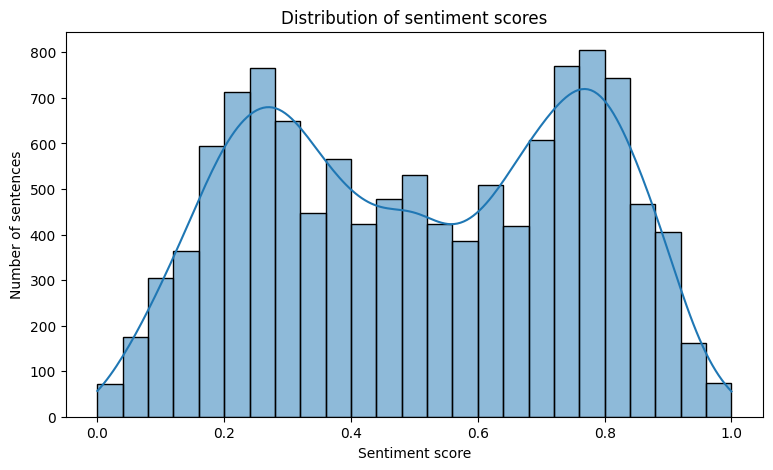

In [33]:
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="sentiment_value",
    bins=25,
    kde=True
)

plt.title("Distribution of sentiment scores")
plt.xlabel("Sentiment score")
plt.ylabel("Number of sentences")
plt.show()

Notice that the distribution is quite symmetric, there is a spike around 0.25 and 0.75 but it is not enough to be considered as a porblematic class imbalance

Now we will discretize the scores by dividing them into 5 classes : "very negative", "negative", "neutral", "positive", "very positive".

In [34]:
bins = [-np.inf, 0.2, 0.4, 0.6, 0.8, np.inf]

labels = [
    "very_negative",
    "negative",
    "neutral",
    "positive",
    "very_positive"
]

clean_df["sentiment_class"] = pd.cut(
    clean_df["sentiment_value"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

In [35]:
class_counts = clean_df["sentiment_class"].value_counts().reindex(labels)

print(class_counts)
print((class_counts / len(clean_df) * 100).round(2))

sentiment_class
very_negative    1510
negative         3140
neutral          2242
positive         3111
very_positive    1852
Name: count, dtype: int64
sentiment_class
very_negative    12.74
negative         26.49
neutral          18.91
positive         26.24
very_positive    15.62
Name: count, dtype: float64


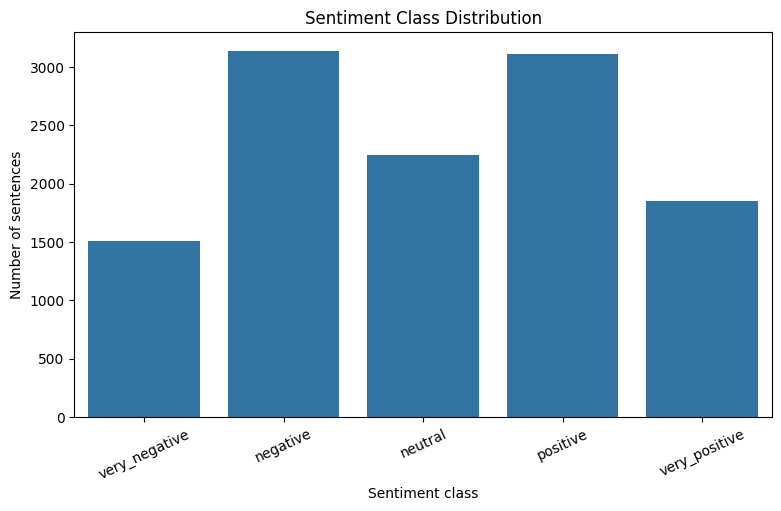

In [36]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=clean_df,
    x="sentiment_class",
    order=labels
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment class")
plt.ylabel("Number of sentences")
plt.xticks(rotation=25)
plt.show()

Let's analyze the sentences lenght and content

In [37]:
clean_df["n_words"] = clean_df["clean text"].str.split().str.len()
# we count words by using whitespace as the separator between each word
clean_df["n_chars"] = clean_df["clean text"].str.len()

clean_df[["n_words", "n_chars"]].describe()

,n_words,n_chars
count,11855.000000,11855.000000
mean,19.168705,102.408857
std,9.206627,50.782076
min,2.000000,4.000000
25%,12.000000,63.000000
50%,18.000000,98.000000
75%,25.000000,137.000000
max,56.000000,267.000000


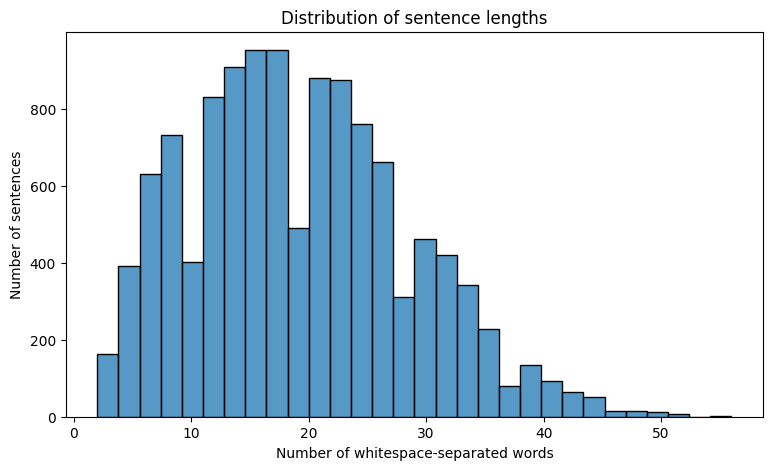

In [38]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="n_words",
    bins=30
)

plt.title("Distribution of sentence lengths")
plt.xlabel("Number of whitespace-separated words")
plt.ylabel("Number of sentences")
plt.show()

In [39]:
clean_df.nsmallest(10, "n_words")[["clean text", "n_words"]]

,clean text,n_words
575,Hopkins .,2
591,Hmm .,2
926,No. .,2
1570,Cool ?,2
1948,Cool .,2
2010,Imperfect ?,2
2206,Go .,2
2389,Amazing !,2
2883,Why ?,2
3696,C'mon !,2


In [40]:
clean_df.nlargest(10, "n_words")[["clean text", "n_words"]]

,clean text,n_words
174,The film is faithful to what one presumes are ...,56
1587,It cuts to the core of what it actually means ...,52
3751,There are n't too many films that can be as si...,52
9060,"Build some robots , haul 'em to the theatre wi...",52
741,... spiced with humor ( ' I speak fluent flatu...,51
3638,"It may not be as cutting , as witty or as true...",51
6656,If you are curious to see the darker side of w...,51
8667,It 's a bad sign when you 're rooting for the ...,51
1255,( City ) reminds us how realistically nuanced ...,50
2042,Sitting in the third row of the IMAX cinema at...,50


Is there any correlation between the sentences lenght and their sentiment ?

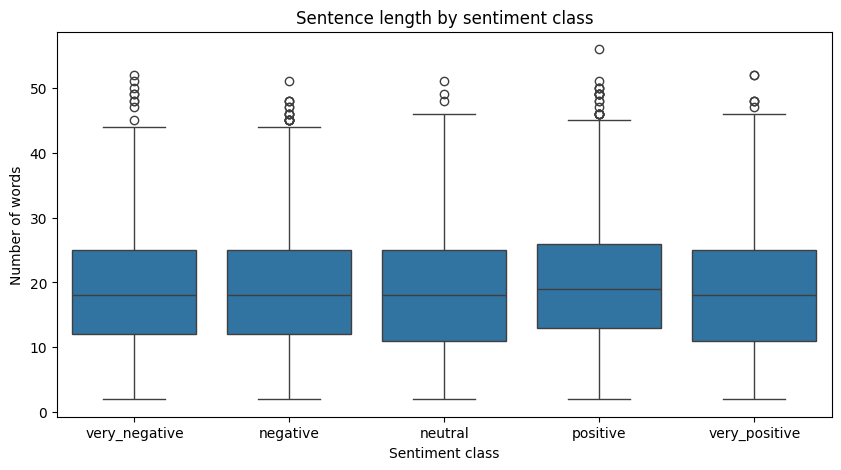

In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=clean_df,
    x="sentiment_class",
    y="n_words",
    order=labels
)

plt.title("Sentence length by sentiment class")
plt.xlabel("Sentiment class")
plt.ylabel("Number of words")
plt.show()

Each sentiment class seem to have equal sentence lenghts

As we saw earlier, the dictionary contained too many short sentences of less than 5 characters and neutral sentiment sentences, so we decided to use the `datasetSentences.txt` file as our text dataset which seems to be ideal for our work

In [42]:
split_counts = clean_df["splitset_label"].value_counts()

print(split_counts)
print((split_counts / len(clean_df) * 100).round(2))

splitset_label
1    8544
2    2210
3    1101
Name: count, dtype: int64
splitset_label
1    72.07
2    18.64
3     9.29
Name: count, dtype: float64


Here the corresponding labels are :  
1 train  
2 test  
3 validation  

In [43]:
split_class_pct = pd.crosstab(
    clean_df["splitset_label"],
    clean_df["sentiment_class"],
    normalize="index"
)*100

print(split_class_pct)

sentiment_class  very_negative   negative    neutral   positive  very_positive
splitset_label                                                                
1                    12.780899  25.959738  19.007491  27.176966      15.074906
2                    12.624434  28.642534  17.601810  23.076923      18.054299
3                    12.624886  26.248865  20.799273  25.340599      14.986376


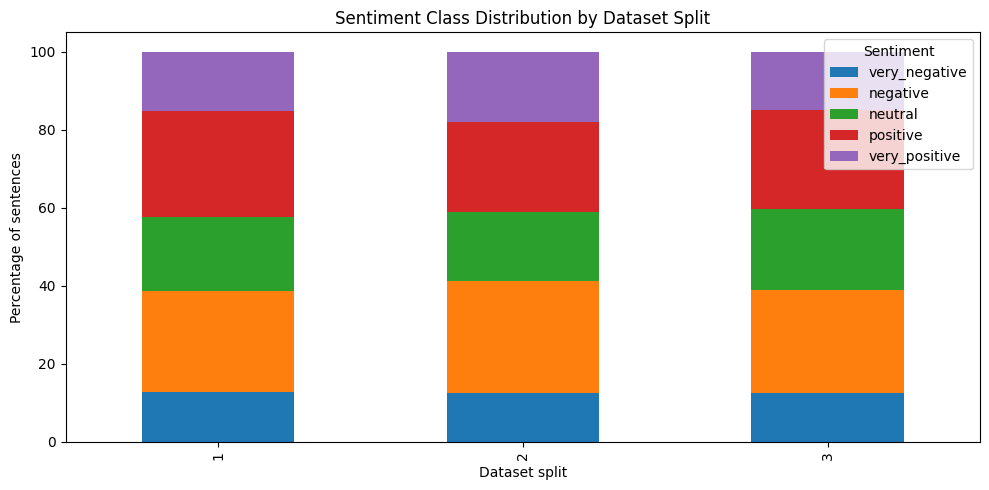

In [44]:
split_class_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)

plt.title("Sentiment Class Distribution by Dataset Split")
plt.xlabel("Dataset split")
plt.ylabel("Percentage of sentences")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

The different sets have similar distributions which is great.

In [45]:
from collections import Counter
import re

def tokenize(text) :
    return re.findall(r"\b\w+\b", text.lower())

all_tokens = [
    token
    for sentences in clean_df["clean text"].dropna()
    for token in tokenize(sentences)
]

word_counts = Counter(all_tokens)

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(word_counts))

word_counts.most_common(20)

Total tokens: 206040
Unique tokens: 17819


[('the', 10209),
 ('a', 7321),
 ('and', 6263),
 ('of', 6148),
 ('to', 4275),
 ('s', 3570),
 ('is', 3562),
 ('it', 3435),
 ('in', 2675),
 ('that', 2658),
 ('as', 1807),
 ('but', 1641),
 ('film', 1600),
 ('with', 1564),
 ('for', 1455),
 ('this', 1446),
 ('movie', 1391),
 ('its', 1339),
 ('an', 1329),
 ('you', 1186)]

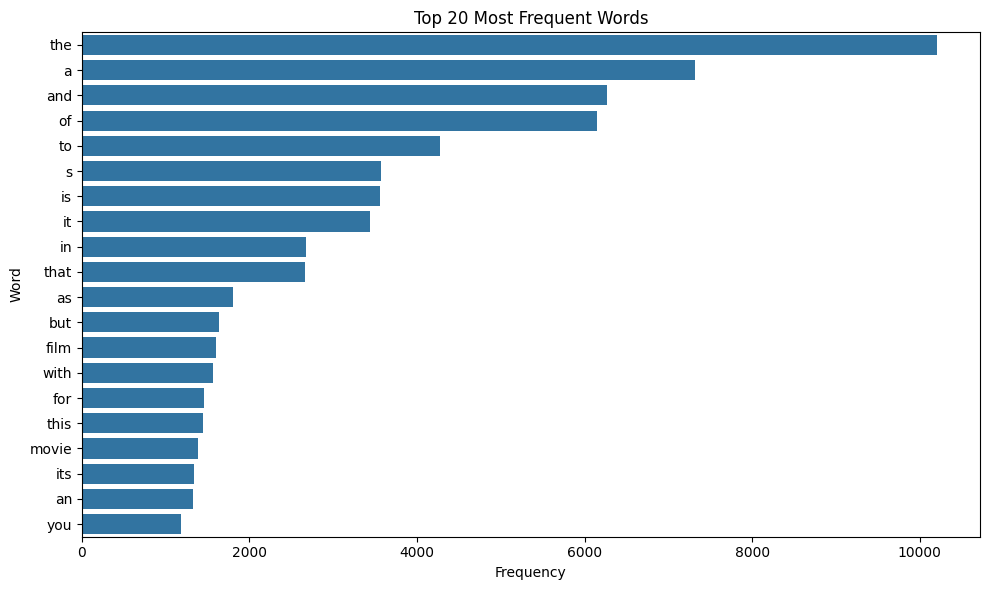

In [46]:
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["word", "count"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="count",
    y="word"
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

In [47]:
positive_texts = clean_df.loc[
    clean_df["sentiment_class"].isin(["positive", "very_positive"]),
    "clean text"
]

negative_texts = clean_df.loc[
    clean_df["sentiment_class"].isin(["negative", "very_negative"]),
    "clean text"
]

positive_counts = Counter(
    token
    for text in positive_texts.dropna()
    for token in tokenize(text)
)

negative_counts = Counter(
    token
    for text in negative_texts.dropna()
    for token in tokenize(text)
)

print("Positive:", positive_counts.most_common(20))
print("Negative:", negative_counts.most_common(20))

Positive: [('the', 4316), ('a', 3321), ('and', 3202), ('of', 2822), ('to', 1649), ('s', 1500), ('is', 1485), ('it', 1364), ('in', 1179), ('that', 1163), ('with', 784), ('film', 770), ('as', 730), ('an', 662), ('but', 623), ('for', 575), ('its', 574), ('this', 567), ('you', 488), ('movie', 480)]
Negative: [('the', 3982), ('a', 2745), ('of', 2247), ('and', 2147), ('to', 1813), ('is', 1420), ('it', 1375), ('s', 1335), ('that', 1043), ('in', 1038), ('as', 761), ('movie', 671), ('this', 628), ('for', 589), ('but', 581), ('film', 545), ('with', 537), ('t', 518), ('its', 513), ('n', 513)]


Finally, we save the our dataframe into a csv file that we will use to train the models

In [48]:
clean_df.to_csv("sentimentClassification.csv", index=False)

In [50]:
clean_df.head()

,sentence_index,sentence,clean text,phrase_id,sentiment_value,splitset_label,sentiment_class,n_words,n_chars
0,1,The Rock is destined to be the 21st Century 's...,The Rock is destined to be the 21st Century 's...,226166,0.69444,1,positive,36,181
1,2,The gorgeously elaborate continuation of `` Th...,The gorgeously elaborate continuation of `` Th...,226300,0.83333,1,very_positive,37,227
2,3,Effective but too-tepid biopic,Effective but too-tepid biopic,13995,0.51389,2,neutral,4,30
3,4,If you sometimes like to go to the movies to h...,If you sometimes like to go to the movies to h...,14123,0.73611,2,positive,21,89
4,5,"Emerges as something rare , an issue movie tha...","Emerges as something rare , an issue movie tha...",13999,0.86111,2,very_positive,23,113
